In [1]:
#General tools
import numpy as np
import pandas as pd
import seaborn as sns
import os
import pymol2

#Coded tools, you need to connect it manually sometimes
from src.generate_graph_new import protein_pocket, make_protein_ligand_complex

#Heatmap tools
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap


In [2]:
#Pocket docking

#Fixed data
dock_pdbqt_dir = '/data/projects/Chemdocking/dock_score/destabilizer_with_poses/'
protein_pdb_dir = "/data/projects/Chemdocking/VirtualDockingLab/data/screen_8000/protein/target.pdb"
complex_pdb_dir = "tmp/complex.pdb"
complex_csv_dir = "complex.csv"
pocket_res = '/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_poses/destabilizers/'


#poweredge/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_poses/stabilizers/0/1


In [52]:
#Docking filtering and selection though ligand name 


#Define iteration through folders
for folder in os.listdir(dock_pdbqt_dir):
    sub_folder= os.path.join(dock_pdbqt_dir, folder)  

    #Define iteration through files
    for file in os.listdir(sub_folder):               
        file_path = os.path.join(sub_folder, file)
        if file.split('.') [1] != 'pdb':
            continue
        if file.split('_') [4] == '95': 
            
            #Make temporary folder                                           
            if not os.path.exists("tmp"):
                os.mkdir("tmp")
                
            # Conver ligand posed pdb file to several sdf files
            ! /home/jrivera/envs/chem/bin/obabel {file_path} -O tmp/ligand_pose_.sdf -m
            
            # Make protein-ligand complex file (take the first ligand pose)
            make_protein_ligand_complex(protein_pdb_dir, "tmp/ligand_pose_1.sdf", complex_pdb_dir)
            
            #From all of the poses, take the ones with distance lower than 6 Armstrong
            pocket = protein_pocket(complex_pdb_dir, ligand_id = 'UNK', threshold = 6)

            #Give your file the correct name
            for folder_res in os.listdir(pocket_res):
                res_path = os.path.join(pocket_res, folder_res)
                if folder_res == '95':
                    csv_file_name = file.split('.')[0] + '.csv'
                    docking_dir = os.path.join(res_path, csv_file_name)
                    pocket.to_csv(docking_dir)
    
            os.system("rm -r tmp") 

1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted
1 molecule converted


In [61]:
#Control checking to see if your re_path directory is good
for folder_res in os.listdir(pocket_res):
    res_path = os.path.join(pocket_res, folder_res)

print(res_path)

/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_poses/destabilizers/32


In [7]:
#Ligand preparation for heatmap


pocket_data_ = os.listdir(pocket_res)        


PAH_ligands= {}


for filename in pocket_data:             
    if filename.split('.') [1] != 'csv':
        continue                         

    #Open only the filtered files
    docking_dir = os.path.join(pocket_res, filename)  

    #Read your filtered files    
    ligands = pd.read_csv(docking_dir)

    #Create a binary data set to represent the data in a heat map
    ligands_processed = [1 if i in list(ligands['index']) else 0 for i in range(453)]

    #Add the data for your dictionary       
    PAH_ligands[filename.split('_')[4]] = ligands_processed
    
    
    #print (PAH_ligands)


In [22]:
#Dictionary sorting
PAH_ligands_sorted = dict(sorted(PAH_ligands.items(), key=lambda item: int(item[0])))

#PAH_ligands.items() it will call the dictionary items ( ,  )
#Transform your data into int to sorted, key=lambda sorted by number, not alphabetically

#print (PAH_ligands_sorted)

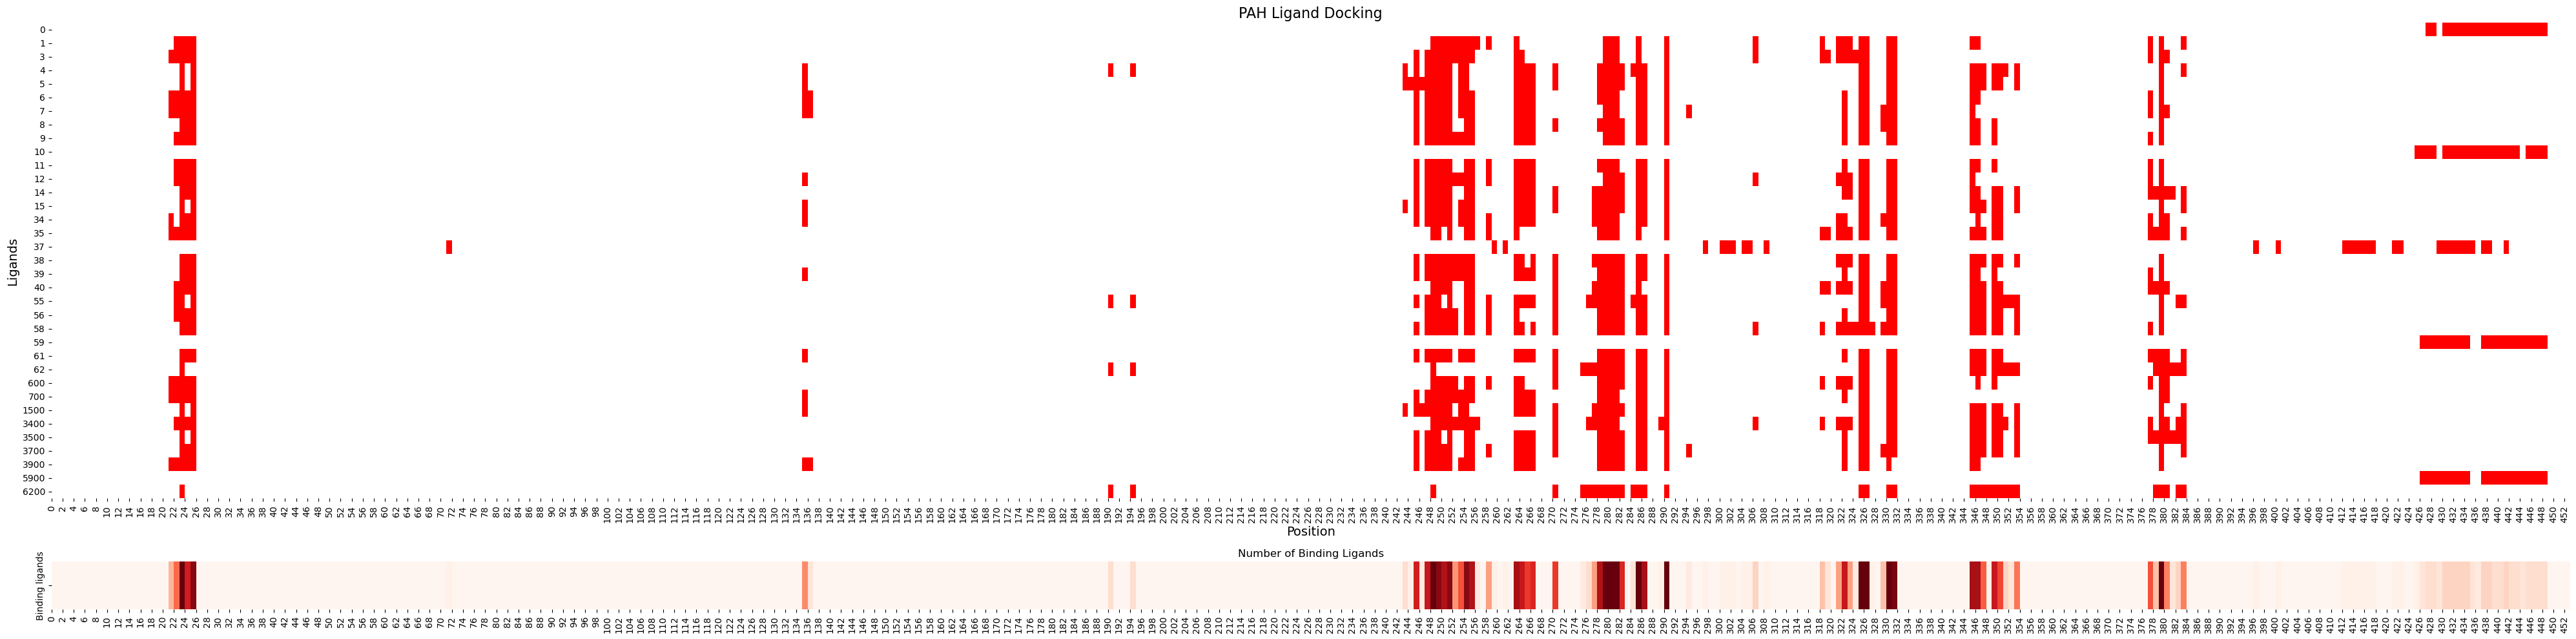

In [23]:

# Create the heatmap layout
fig, ax = plt.subplots(2, 1, figsize=(40, 10), 
                      gridspec_kw={'height_ratios': [1, 0.1]})

# Define x-tick positions (every 2 from 0 to 452)
xticks = np.arange(0, 453, 2)


# Transpose sorted ligand data so ligands are rows
PAH_ligands = pd.DataFrame(PAH_ligands_sorted).T

# Plot main heatmap (binary matrix)
sns.heatmap(PAH_ligands, cmap=["white", "red"], cbar=False, ax=ax[0], 
            linewidths=0.001, linecolor='gray')

# Title and labels
ax[0].set_title('PAH Ligand Docking', fontsize=16)
ax[0].set_xlabel('Position', fontsize=14)
ax[0].set_ylabel('Ligands', fontsize=14)
ax[0].tick_params(axis='x', rotation=90)
ax[0].set_xticks(xticks)
ax[0].set_xticklabels(xticks)

# Compute sum of 1s per column
heatmap_sum = (PAH_ligands == 1).sum(axis=0)
df_heatmap_sum = pd.DataFrame([heatmap_sum], index=["Binding ligands"])



# Plot summary heatmap (only one row)
sns.heatmap(df_heatmap_sum, ax=ax[1], cmap="Reds", cbar=False, 
            annot= False, fmt="")
ax[1].set_title("Number of Binding Ligands", fontsize=12)
ax[1].set_xlabel('')
ax[1].set_ylabel('')
ax[1].tick_params(axis='x', rotation=90)
ax[1].set_xticks(xticks)
ax[1].set_xticklabels(xticks)

# Show the figure
plt.tight_layout()
plt.savefig('/projectbig/jupyternotebook/jrivera/output/figures/Docking/Ligands_stabilizers_v3.pdf')
plt.show()
